In [1]:
# ! means that it runs through terminal
!pip install zerosyl

!pip install tgt

# wget downloads things directly from the internet
#!wget https://storage.googleapis.com/zerospeech-checkpoints/5895-34629-0010.flac
#!wget https://storage.googleapis.com/zerospeech-checkpoints/5895-34629-0010.TextGrid

In [2]:
# import all relevant functions and or libraries
import matplotlib.pyplot as plt
import numpy as np
import tgt
import torch
import torchaudio
from IPython.display import Audio, display
from scipy.cluster.hierarchy import cut_tree, linkage
from scipy.signal import find_peaks

from zerosyl import WavLM

plt.rcParams["font.family"] = "monospace"

In [3]:

# create an instance of wavlm model with pretrained weights gotten from "remote"
wavlm = WavLM.from_remote()



In [4]:
# wav contains the audio data, where as sr contains the sample rate of the audio (hz)
#wav, sr = torchaudio.load("5895-34629-0010.flac")

wav, sr = torchaudio.load("id_3_main_post_test.wav")
# here we can see that sr matches the rate we display the audio at (16000 hz)
print(f"Original sample rate: {sr}")
display(Audio(wav, rate=16000))

Original sample rate: 16000


In [5]:
# preprocessing of the waveform
# loudness normalization
wav = torch.nn.functional.layer_norm(wav, wav.shape) # this ensures that one audio recording with very loud audio and another one with soft audio are both normalized to be the same aduio
# zero-pad such that the output features will be perfectly aligned with 20ms intervals
wav = torch.nn.functional.pad(wav, ((400 - 320) // 2, (400 - 320) // 2))

In [6]:
#Extract boundary features from layer 13
# the model has x amount of layers, at the 13th layer, we extract the feature vectors and look at what is going on in them 
# note how we are doing it for our audio sampe wav, so the features we extract will be unique to wav
with torch.inference_mode():
    boundary_features, _ = wavlm.extract_features(wav, output_layer=13)

# some kind of normalization or reduction technique

#numpy turns py torch tensor to numpy array. Changes data format, makes it easier to work with
#squeeze(0) removes the 0th dimension
    #Original shape: [1, time_steps, feature_dim]
    #After squeeze: [time_steps, feature_dim]
boundary_features = boundary_features.squeeze(0).cpu().numpy()

#display how many/ dimensionality of vectors [time_steps/ frames = 108, feature_dim = 1024]
# note feature dimension depends on lm model used, since we use wavLM large, it will alwys be 1024
boundary_features.shape

(3788, 1024)

In [7]:
#Perform boundary detection using peak detection on smoothed L2 norms

# compute the L2 norm signal
norms = np.linalg.norm(boundary_features, axis=-1)
#print(norms) gives you 108 distances, i.e. the magnitudes of the vectors
# normalize the norm signal
norms = (norms - norms.mean()) / norms.std()
# takes those magniturdes and normalises them so that they are centered around 0


# smooth the L2 norm signal
kernel = np.ones(3) / 3 # kernal is moving average, takes average of 3 neigbouring values
pad_len = 3 // 2 # pad_len adds one value on each side of norms vector, both on start and finish, adding 2 in total
norms_padded = np.pad(norms, (pad_len, pad_len), mode="edge") # adds padding to norms, makes smoothing possible
norms_smooth = np.convolve(norms_padded, kernel, mode="valid") # averages out values so that you get less jaggedness

# why smooth?
#Removes high-frequency noise
#Emphasizes meaningful acoustic changes
#Reduces false positives in peak detection

# performan prominence based peak detection
peaks, _ = find_peaks(norms_smooth, prominence=0.45)
# 0.45 is the minimum height relative to surrounding valeys for a peak to be detected
print(peaks)

# use peaks to detemine boundaries
boundaries = [0] + peaks.tolist() + [len(boundary_features)] # very simply adding start and finish to boundraries
print(boundaries)

[   5   16   42   54   64   83   99  111  126  132  141  146  162  172
  197  207  218  233  251  261  269  280  296  313  322  332  340  350
  362  385  396  400  410  415  425  439  456  466  489  496  500  509
  518  531  545  562  575  593  607  617  625  635  644  662  670  678
  695  708  720  730  738  748  762  770  782  790  796  804  816  837
  852  861  869  895  904  919  930  951  963  969  980  992 1003 1018
 1029 1042 1065 1086 1097 1110 1129 1133 1141 1150 1169 1178 1187 1202
 1214 1221 1230 1245 1268 1281 1305 1315 1328 1339 1350 1368 1380 1392
 1402 1414 1430 1444 1461 1482 1502 1512 1528 1538 1549 1564 1580 1594
 1606 1614 1622 1640 1651 1657 1669 1678 1691 1695 1701 1712 1720 1731
 1743 1750 1757 1768 1779 1803 1814 1822 1834 1847 1852 1860 1880 1898
 1912 1920 1931 1942 1959 1971 1984 1999 2038 2055 2070 2085 2095 2109
 2118 2131 2145 2159 2172 2180 2191 2200 2211 2235 2248 2266 2275 2285
 2301 2312 2329 2338 2348 2358 2371 2395 2401 2414 2433 2458 2469 2485
 2492 

In [8]:


textgrid = tgt.read_textgrid("id_3_main_post_test_syllables.TextGrid")
# textgrid = None



In [9]:
# compute mel spectrogram
tMel = torchaudio.transforms.MelSpectrogram(
    n_fft=1024,
    win_length=400,
    hop_length=320,
)
tDB = torchaudio.transforms.AmplitudeToDB(top_db=80) #log scale: changes its scale to better match human perception (higher frequencies are harder to distinguish for humans than lower ones)

melspec = tDB(tMel(wav.squeeze()))

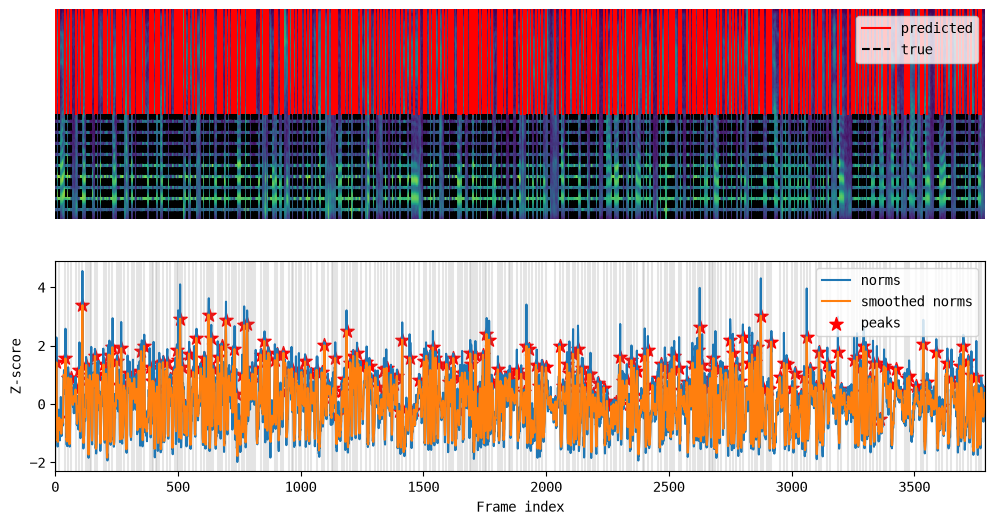

In [10]:


xmin, xmax = 0, melspec.size(1)

plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.imshow(melspec, aspect="auto", origin="lower")
plt.axis("off")
for i, b in enumerate(peaks):
    plt.axvline(b, ymin=0.5, c="r", label="predicted" if i == 0 else None)

if not textgrid is None:
    for i, interval in enumerate(textgrid.get_tier_by_name("syllables")):
        x1 = interval.start_time * 50
        x2 = interval.end_time * 50
        plt.axvline(
            x1, ymax=0.5, c="k", linestyle="--", label="true" if i == 0 else None
        )
        plt.axvline(x2, ymax=0.5, c="k", linestyle="--")
plt.xlim(xmin, xmax)
plt.legend()

plt.subplot(2, 1, 2)
for b in boundaries:
    plt.axvline(b, c="gray", alpha=0.2)

peaks_x = peaks
peaks_y = norms_smooth[peaks_x]

plt.plot(norms, label="norms")
plt.plot(norms_smooth, label="smoothed norms")
plt.scatter(peaks_x, peaks_y, marker="*", label="peaks", color="red", s=100)
plt.xlim(xmin, xmax)
plt.xlabel("Frame index")
plt.ylabel("Z-score")
plt.legend()




In [11]:


listen_samples = []
listen_samples.append(np.zeros(8000))
for start_frame, end_frame in zip(boundaries[:-1], boundaries[1:]):
    listen_samples.append(wav[0, start_frame * 320 : end_frame * 320])
    listen_samples.append(np.zeros(8000))
listen_samples = np.concat(listen_samples, axis=0)
display(Audio(listen_samples, rate=16000))



In [12]:
# now extract semantic features from higher layer (22)
# what is a semantic? it is meaning, low is fact, higher is meaning
with torch.inference_mode():
    semantic_features, _ = wavlm.extract_features(wav, output_layer=22)

semantic_features = semantic_features.squeeze(0)

semantic_features.shape

torch.Size([3788, 1024])

In [13]:
starts = torch.tensor(boundaries[:-1], device=wav.device)
ends = torch.tensor(boundaries[1:], device=wav.device)
embeddings = [
    semantic_features[start:end].mean(dim=0) for start, end in zip(starts, ends)
]
embeddings = torch.stack(embeddings)

In [14]:
embeddings.shape

torch.Size([285, 1024])

In [15]:


# Load the K-Means centroids
centroids = torch.hub.load_state_dict_from_url(
    "https://storage.googleapis.com/zerospeech-checkpoints/zerosyl-v040-centroids-k-10000.pt"
)
# Find the ID of the nearest centroid
ids = torch.cdist(embeddings.cpu(), centroids).argmin(1)



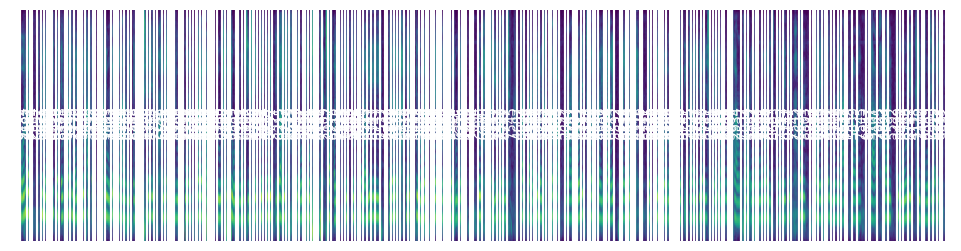

In [16]:
plt.figure(figsize=(12, 3))
plt.subplot(1, 1, 1)
plt.imshow(melspec, aspect="auto", origin="lower")
plt.axis("off")
for b1, b2, id in zip(boundaries[:-1], boundaries[1:], ids):
    plt.axvline(b1, c="w")
    plt.axvline(b2, c="w")
    plt.text(
        (b1 + b2) / 2, 64, str(id.item()), rotation=90, c="w", ha="center", va="center"
    )


In [17]:


# agglomerative clustering
linkage_matrix = linkage(
    centroids.numpy(), method="ward", metric="euclidean", optimal_ordering=False
)
# cut dendrogram into 2 main branches
silences = cut_tree(linkage_matrix, 2)[:, 0]
# the smaller branch should be silences
if silences.sum() > (1 - silences).sum():
    silences = 1 - silences
# to torch tensor
silences = torch.from_numpy(silences).bool()



In [18]:
print(silences[ids])

tensor([ True, False, False, False, False, False,  True, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False,  True, False, False, False, False,
        False, False, False, False, False, False, False, False,  True, False,
        False, False, False, False, False, False, False,  True, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
         True, False, False, False, False, False, False, False,  True,  True,
        False, False, False, False, False, False, False, False, False,  True,
         True,  True,  True, False, False, False, False, False, False, False,
        False, False,  True, False, False,  True,  True,  True, False, False,
        False, False, False, False, False, False, False, False,  True, False,
        False, False, False, False,  True, False, False, False, 

In [19]:
order = torch.argsort(silences)  # [0,0,....,0,0,1,1,...,1,1]
SIL = torch.argmax(silences[order].long()).item()  # position of first 1
mapping = torch.empty_like(order)
mapping[order] = torch.arange(len(order))
mapping[mapping > SIL] = SIL

print(f"The new (single) silence token has the ID: {SIL}")

The new (single) silence token has the ID: 9115


In [20]:
ids_remapped = mapping[ids]

ids_remapped

tensor([9115, 2817, 2518, 7784, 2099, 8446, 9115, 6042, 3197, 7935, 2040, 7593,
        8181, 2040, 4285, 2432,  343, 7517, 5913, 5124, 2407, 3018, 7222, 6330,
        8359, 9115, 1121, 2710, 4658, 1053, 1053, 5507,   25, 2799, 4096,  343,
        2799, 2817, 9115,  201, 1140,  245, 5780, 2099, 4757, 2799, 4067, 9115,
        2131,  343,   44, 2758,  460, 2706,  574, 2799, 7310, 4757, 1365, 4368,
        7784,  343,  343, 7223, 7363,   91, 5926, 5926, 2323, 2706, 9115, 6330,
        1532,  245, 1053, 2432, 2518, 1044, 9115, 9115, 7930, 7593, 3289, 8181,
        6464, 2817, 7573,  343, 2817, 9115, 9115, 9115, 9115, 7517, 2165, 6963,
        4506, 7494, 5662, 8498,  343, 2817, 9115, 5681,  343, 9115, 9115, 9115,
        3289, 6556, 3289, 8181, 6246, 7517,  343, 2817, 2817, 2817, 9115, 2817,
        2799, 1053, 1752, 3498, 9115, 1121, 2040, 7593, 3042, 7517, 2518, 5506,
        1053, 9115, 9115, 1140, 8268, 7784, 7517, 2977, 2799, 3942,  201, 2758,
        8972, 6464,  343, 8181, 7930, 65

In [21]:


not_repeated = torch.ones_like(ids_remapped, dtype=torch.bool)
not_repeated[1:] = ~torch.logical_and(
    ids_remapped[1:] == ids_remapped[:-1], ids_remapped[1:] == SIL
)
is_end = torch.ones_like(ids_remapped, dtype=torch.bool)
is_end[:-1] = ~torch.logical_and(
    ids_remapped[1:] == ids_remapped[:-1], ids_remapped[1:] == SIL
)
starts_merged = starts[not_repeated]
ends_merged = ends[is_end]
ids_merged = ids_remapped[not_repeated]



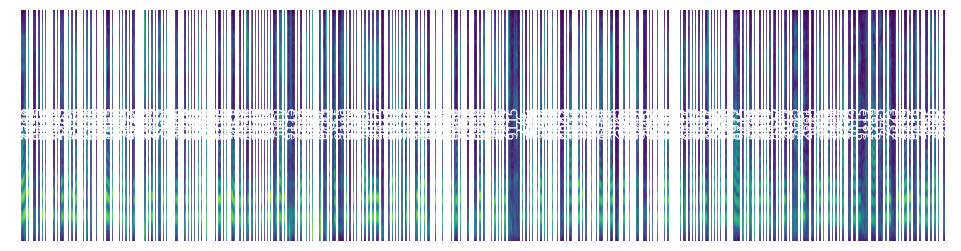

In [22]:
plt.figure(figsize=(12, 3))
plt.subplot(1, 1, 1)
plt.imshow(melspec, aspect="auto", origin="lower")
plt.axis("off")
for start, end, id in zip(starts_merged, ends_merged, ids_merged):
    plt.axvline(start, c="w")
    plt.axvline(end, c="w")
    plt.text(
        (start + end) / 2,
        64,
        str(id.item()),
        rotation=90,
        c="w",
        ha="center",
        va="center",
    )

In [23]:
import tgt

# starts_merged / ends_merged are frame indices (20 ms/frame -> 50 frames per second,
# since hop_length=320 at sr=16000). Convert to seconds using the actual sample rate.
frame_rate = sr / 320

syl_tier = tgt.IntervalTier(
    start_time=0.0,
    end_time=ends_merged[-1].item() / frame_rate,
    name="syllables",
)

for start, end, syl_id in zip(starts_merged, ends_merged, ids_merged):
    xmin = start.item() / frame_rate
    xmax = end.item() / frame_rate
    if xmax <= xmin:
        continue  # skip degenerate zero-length intervals
    # leave silence intervals blank, like the "" intervals in the example TextGrid
    label = "" if syl_id.item() == SIL else str(syl_id.item())
    syl_tier.add_interval(tgt.Interval(xmin, xmax, label))

syllable_textgrid = tgt.TextGrid()
syllable_textgrid.add_tier(syl_tier)

# id number for this recording, e.g. "5" for id_5_main_post_test.wav
output_id = "id_3_main_post_test"
output_path = f"ZeroSyl_{output_id}_syllables.TextGrid"

tgt.write_to_file(syllable_textgrid, output_path, format="long")
print(f"Saved {output_path}")

Saved ZeroSyl_id_3_main_post_test_syllables.TextGrid
